# 06 · Consolidación de perfiles y fichas

**Fuente:** INE CCPC 2009–2024, bases adjuntas. No hay datos personales.

## Propósito
Validar los resultados visibles por el dashboard y probar el flujo de creación de una ficha educativa sin datos personales ni difusión automatizada.

In [1]:
import json
import pandas as pd
from pathlib import Path
p=Path('datos/processed/producto')
profiles=pd.DataFrame(json.loads((p/'perfiles.json').read_text()))
profiles[['perfil_id','nombre','n_unidades','media_presidencial','media_intermedia','cambio_presidencial_pp','cambio_intermedia_pp']]

,perfil_id,nombre,n_unidades,media_presidencial,media_intermedia,cambio_presidencial_pp,cambio_intermedia_pp
0,1,Participación baja; descenso presidencial,1366,46.61,34.57,-9.83,3.35
1,2,Participación media-baja; aumento intermedio,1872,58.98,45.01,0.30,18.68
2,3,Participación media-alta; descenso presidencial,1964,64.33,56.96,-9.05,0.21
3,4,Participación media-alta; crecimiento intermedio,1259,68.66,52.69,11.42,33.45
4,5,Participación alta; comportamiento sostenido,2080,77.56,69.11,-1.41,14.90


## Distribución y medidas descriptivas
Los promedios de cada perfil son **no ponderados**. K-Means tiene cinco clusters exploratorios; k=4 obtiene mejor silhouette.

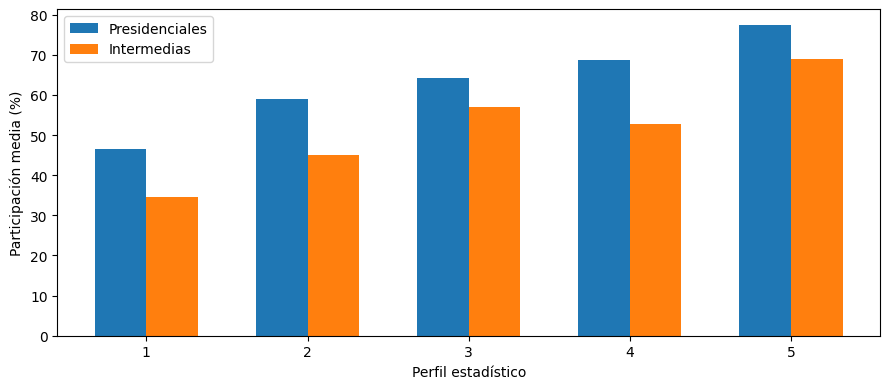

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(9,4));
x=profiles.perfil_id.to_numpy();ax.bar(x-.16,profiles.media_presidencial,width=.32,label='Presidenciales');ax.bar(x+.16,profiles.media_intermedia,width=.32,label='Intermedias');ax.set_xticks(x);ax.set_xlabel('Perfil estadístico');ax.set_ylabel('Participación media (%)');ax.legend();plt.tight_layout();plt.show()

## Inferencia en CSV agregado
Solo observaciones con tasas, observados y NS para los **seis años**. Datos futuros aislados no son compatibles con este modelo.

In [3]:
from src.dashboard_api import classify_dataframe
sample=pd.read_csv('samples/plantilla_clasificacion_ejemplo_SINTETICO.csv')
classified=classify_dataframe(sample)
classified[['unidad_id','perfil_id','perfil_nombre','distancia_centroide']]

,unidad_id,perfil_id,perfil_nombre,distancia_centroide
0,MUESTRA_SINTETICA,2,Participación media-baja; aumento intermedio,0.866358


## Flujo editorial asistido (determinista)
Los módulos funcionan como agentes especializados de datos, redacción y verificación; la aprobación humana se realiza aparte en la interfaz. No hay IA generativa externa en esta versión.

In [4]:
from src.education import build_draft,pdf_for_draft
item=build_draft(profiles.iloc[0].to_dict())
print('validación:',item['validation'])
print('requiere aprobación humana:',item['requires_human_approval'])
print(item['draft']['resumen'])
print('bytes PDF de muestra:',len(pdf_for_draft(item,'BORRADOR — NO APROBADO','Sin revisión')))

validación: {'passed': True, 'checks': ['cifras respaldadas por perfil', 'sin afirmaciones sobre comportamiento individual', 'sin exhortación partidista o persuasión demográfica'], 'checked_at': '2026-10-28T03:57:25.931844+00:00'}
requiere aprobación humana: True
Este grupo estadístico comprende 1,366 unidades municipio × edad. En las elecciones presidenciales presenta una participación media de 46.6%, mientras que en las intermedias la media es de 34.6%.
bytes PDF de muestra: 24156


## Conclusión
Panel, modelo y generación de borradores se pueden operar en VS Code. La homologación geométrica y el despliegue público quedan expresamente fuera del MVP.